# 05 · Explicabilidad con SHAP
¿Qué variables mueven las predicciones? Usamos SHAP (TreeExplainer) sobre los modelos finales.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, polars as pl, duckdb
import matplotlib.pyplot as plt, seaborn as sns
from ypf_ds import config
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.figsize"] = (11, 4.5)
config.DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

In [2]:
import joblib, shap
from ypf_ds.features import build as fb
panel, pozos = pl.read_parquet(config.PANEL), pl.read_parquet(config.POZOS)
def muestra_a(fluido, n=4000):
    art = joblib.load(config.DIR_MODELOS / f"{fluido}_existente.joblib")
    df = fb.dataset_modo_a(panel, pozos, fluido, horizontes=[1, 6, 12])
    df = df.filter(pl.Series(fb.particion_temporal(df["fecha_obj"]) == "test")).sample(n, seed=42)
    X, _ = fb.a_pandas(df, art["columnas"], art["categoricas"], art["categorias"])
    return art, X

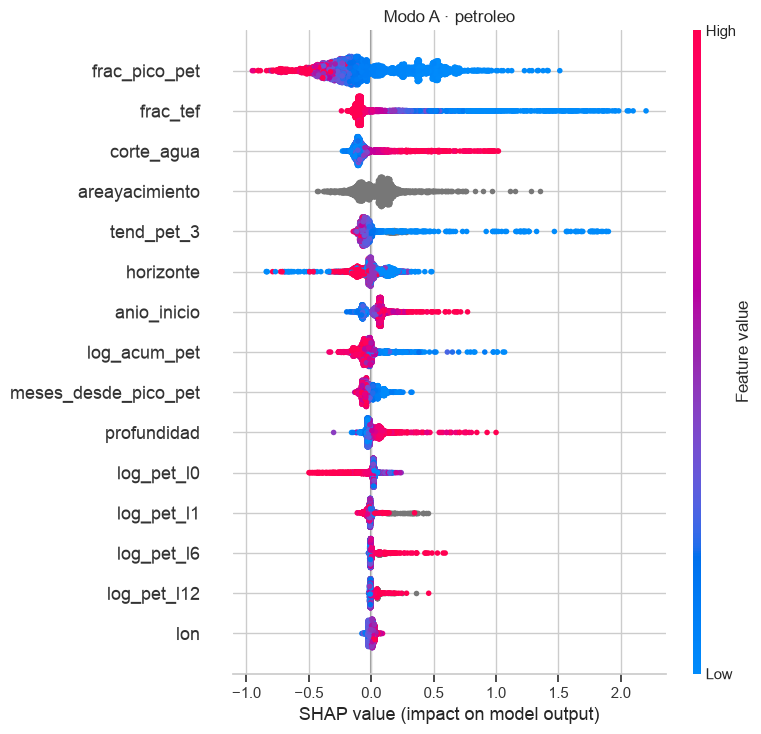

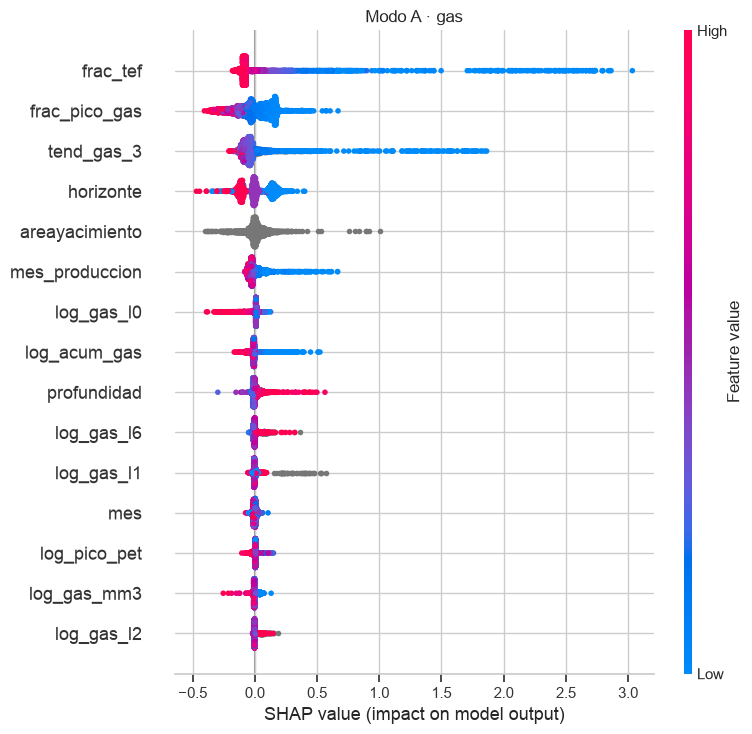

In [3]:
for fluido in ["petroleo", "gas"]:
    art, X = muestra_a(fluido)
    sv = shap.TreeExplainer(art["modelos"]["p50"]).shap_values(X)
    plt.figure(); shap.summary_plot(sv, X, max_display=15, show=False)
    plt.title(f"Modo A · {fluido}"); plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / f"05_shap_A_{fluido}.png", dpi=110); plt.show()

En el modo A dominan el **horizonte**, la **posición respecto del pico** (`frac_pico`, meses desde el pico), la **tendencia reciente** y los **meses en producción**: el modelo aprendió la física de la declinación (los pozos jóvenes declinan rápido, los maduros se estabilizan).

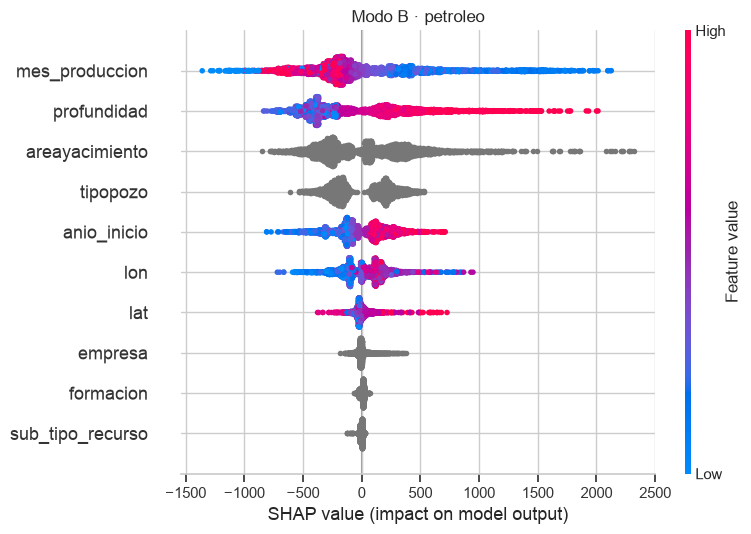

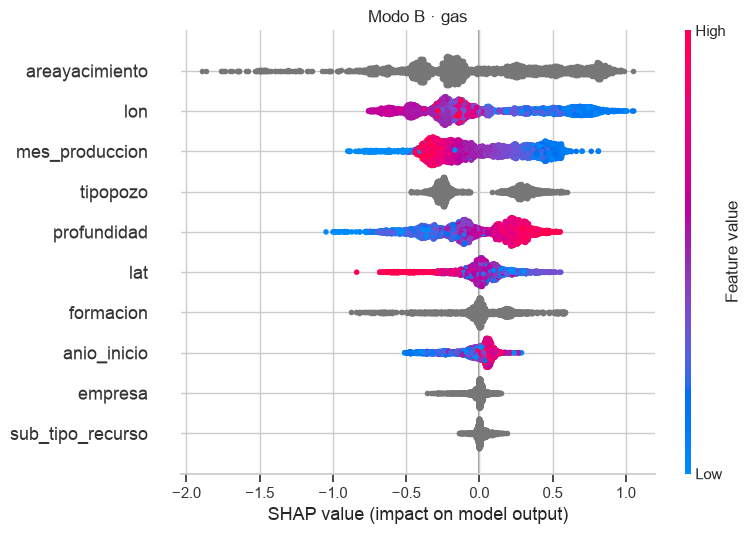

In [4]:
for fluido in ["petroleo", "gas"]:
    art = joblib.load(config.DIR_MODELOS / f"{fluido}_nuevo.joblib")
    df = fb.dataset_modo_b(panel, pozos, fluido).sample(4000, seed=42)
    X, _ = fb.a_pandas(df, art["columnas"], art["categoricas"], art["categorias"])
    sv = shap.TreeExplainer(art["modelos"]["p50"]).shap_values(X)
    plt.figure(); shap.summary_plot(sv, X, show=False)
    plt.title(f"Modo B · {fluido}"); plt.tight_layout(); plt.savefig(config.DIR_FIGURAS / f"05_shap_B_{fluido}.png", dpi=110); plt.show()

En el modo B (pozo nuevo) pesan el **tipo de pozo declarado**, la **formación**, la **ubicación** (lat/lon, yacimiento) y el **año de inicio**: los pozos más recientes tienen ramas laterales más largas y más etapas de fractura, lo que se ve como una tendencia creciente de productividad por año.

### Reflexión: sesgos y límites
- **Sesgo de representación:** Vaca Muerta y YPF concentran la mayoría de los datos; para formaciones u operadoras con pocos pozos la predicción es menos confiable.
- **Variables omitidas:** el dataset no tiene longitud de rama lateral, número de etapas ni volumen de agente de sostén, que son los principales determinantes de productividad. El año de inicio actúa como un *proxy* imperfecto.
- **Drift:** la tecnología de completación mejora año a año; un pozo de 2027 probablemente rinda más de lo que el modelo predice. Hay que reentrenar periódicamente.
- **Uso responsable:** la predicción es orientativa, no reemplaza un estudio de reservorio ni debe usarse sola para decisiones de inversión.